In [1]:
import pandas as pd
import numpy as np
import pickle

In [2]:
# alldata_dicts = []
# # journal = 'Cement_and_Concrete_Composites'
# for journal in ['Cement_and_Concrete_Research', 'Cement_and_Concrete_Composites','Construction_and_Building_Materials']:
#     res = pickle.load(open(f'./{journal}/res_discomat_r1.pkl','rb'))
#     alldata = pickle.load(open(f'./{journal}/pii_table_dict.pkl','rb'))
#     reslist = res['pred_tuples']
#     alldata_dicts.append(alldata)

In [3]:
# df = pd.read_csv('composition_cls.csv')
df = pd.read_csv('composition_cls_slag_updated.csv')
dfall = pd.read_csv('ox_all_compounds_with_dates.csv')

In [4]:
dfs = df[df['SiO2'].between(11,62)]
dfsa = dfs[dfs['Al2O3'].between(10,40)]
dfcas = dfsa[dfsa['CaO'].between(9,65)]
dfcas[dfcas[['SiO2','Al2O3','CaO']].sum(axis=1)>98]

,SiO2,Al2O3,Fe2O3,CaO,Na2O,K2O,MgO,SO3,mid,pii_tid,label,total
346,17.70,25.40,0.00,55.60,0.000,0.000,0.00,0.00,S0008884601005373_2_1_1_0_S-1,S0008884601005373_2,[],98.700
347,13.00,33.20,0.00,52.70,0.000,0.000,0.00,0.00,S0008884601005373_2_1_2_0_S-2,S0008884601005373_2,[],98.900
3329,28.00,20.80,0.00,51.10,0.000,0.000,0.00,0.00,S0008884614000684_2_1_1_0_A-1,S0008884614000684_2,[],99.900
3330,27.20,22.50,0.00,50.20,0.000,0.000,0.00,0.00,S0008884614000684_2_2_1_0_A-2,S0008884614000684_2,[],99.900
3331,26.60,24.10,0.00,49.20,0.000,0.000,0.00,0.00,S0008884614000684_2_3_1_0_A-3,S0008884614000684_2,[],99.900
3332,26.50,24.40,0.00,48.90,0.000,0.000,0.00,0.00,S0008884614000684_2_4_1_0_A-4,S0008884614000684_2,[],99.800
3338,22.00,36.80,0.00,41.20,0.000,0.000,0.00,0.00,S0008884614000684_3_1_1_0_A-5,S0008884614000684_3,[],100.000
3339,22.20,36.70,0.00,41.10,0.000,0.000,0.00,0.00,S0008884614000684_3_2_1_0_A-6,S0008884614000684_3,[],100.000
3560,43.00,37.00,0.00,20.00,0.000,0.000,0.00,0.00,S0008884615000502_0_1_8_0_G*,S0008884615000502_0,[],100.000
4967,59.40,26.70,0.00,13.90,0.000,0.000,0.00,0.00,S0008884618305052_0_2_4_0_G4,S0008884618305052_0,[],100.000


In [5]:
dfall['label'] = df['label']

In [6]:
df = dfall.copy()

In [8]:
df.label.value_counts()

label
[]           34499
[0]           2185
[2]           1764
[3]           1064
[1]            857
[4]             34
[0, 3]          23
[2, 3]          10
[0, 1]           7
[0, 2, 3]        6
[0, 2]           3
[1, 3]           2
Name: count, dtype: int64

In [9]:
str_list = [['fly ash', 'pfa', 'fa', 'pulverized fuel ash'],
 ['calcined clay', 'cc', 'metakaolin', 'mk', 'calcined kaolinite'],
 ['slag', 'ggbs', 'bfs','bofs','eafs'], # added bfs and eafs
 ['silica fume', 'sf', 'fumed silica'],
 ['pumice']]

ignored_list = [['portland','cement','clinker','opc','plc','ppc','psc','cac','csa','cem','pc','c3s','c2s','c3a','c4af','ca2'],
                ['gypsum','anhydrite','hemihydrate','caso4','gp','pg'],
                ['limestone','caco3','dolomite','calcite','vaterite','magnesite','aragonite','ls','lime','lp'],
                ['tailings','bauxite'],
                ['magnetite'],
                ['glass','tile','ceramic'],
                ['reaction product','monosulfate','monosulfoaluminate','ettringite','afm','aft','hydrogarnet','hydrotalcite','carboaluminate','hemicarbonate','monocarbonate','fridel','kuzel','hydroxide'],
                ['strength','rcpt','resistivity','shrinkage','modulus','porosity',"f'c",'fc','evaporable'],
                ['physical','hydration','reactivity','doh','dor'],
                ['et al','et.','rmc'],
                ['aggregate','agg','sand','mud','qtz','quartz'],
                ['clay','kaolin']]

In [10]:
def labeller(x):
    label = []
    for wlist in ignored_list:
        for w in wlist:
            x = str(x)
            if w in x.lower():
                if w not in label:
                    label.append(wlist[0])
    return str(label)

In [32]:
caption_dict = dict()
for p in alldata_dicts:
    for pii in list(p.keys()):
        for tid, table in enumerate(p[pii]):
            
            caption_dict[f'{pii}_{tid}'] = table['caption']

In [33]:
df['caption'] = df.pii_tid.apply(lambda x: caption_dict[x])

In [34]:
# df.caption.apply(lambda  x: 'Theo.' in x)

In [35]:
# dfnolabel.mid[0]

In [36]:
dfnolabel =  df[df.label=='[]']
# dfnolabel['caption_id'] = dfnolabel['caption'] + '_' + dfnolabel.mid
# dfnolabel['r1'] = dfnolabel.mid.apply(lambda x: labeller(x))
dfnolabel['caption_id'] =  dfnolabel.mid

dfnolabel['r1'] = dfnolabel.caption_id.apply(lambda x: labeller(x))

/var/tmp/pbs.150472.pbshpc/ipykernel_18852/44895985.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfnolabel['caption_id'] =  dfnolabel.mid
/var/tmp/pbs.150472.pbshpc/ipykernel_18852/44895985.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfnolabel['r1'] = dfnolabel.caption_id.apply(lambda x: labeller(x))


In [37]:
def combiner(x):
    try:
        return ast.literal_eval(x)[0]
    except:
        return []

In [38]:
dfnolabel['r2'] = dfnolabel.r1.apply(lambda x: combiner(x))

/var/tmp/pbs.150472.pbshpc/ipykernel_18852/1176710538.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfnolabel['r2'] = dfnolabel.r1.apply(lambda x: combiner(x))


In [39]:
import ast

In [40]:
dfnolabel.r2.value_counts() # get cleaner version of it by not just taking the first entry

r2
[]    34499
Name: count, dtype: int64

In [41]:

ignored_labels = list(dfnolabel.r2.value_counts().index)
ignored_freq = list(dfnolabel.r2.value_counts().values)

In [42]:
r11 = dfnolabel['r1'].astype(str)
dfnolabel['r1'] = r11

/var/tmp/pbs.150472.pbshpc/ipykernel_18852/3201504308.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfnolabel['r1'] = r11


In [43]:
dfportland = dfnolabel[dfnolabel.r1.apply(lambda x: 'portland' in x)]

In [44]:
dfnolabel.shape

(34499, 494)

In [46]:
# dfnolabel

In [47]:
dfnolabel.to_csv('./data/nonscm_labelled_ox_all_with_dates_captions.csv')

In [38]:
# dfportland.to_csv('

Index(['SiO2', 'Al2O3', 'Fe2O3', 'CaO', 'Na2O', 'K2O', 'MgO', 'SO3', 'mid',
       'pii_tid', 'label', 'total', 'caption', 'caption_id', 'r1', 'r2'],
      dtype='object')

In [11]:
dfnolabel = pd.read_csv('./nonscm_labelled_ox_all_with_dates_captions.csv')

In [12]:
dfnolabel.r1.value_counts()

r1
[]                                                                26455
['portland', 'portland']                                           2951
['portland']                                                       2001
['gypsum']                                                          532
['limestone']                                                       448
['aggregate']                                                       312
['limestone', 'limestone']                                          294
['et al']                                                           280
['portland', 'portland', 'portland']                                238
['glass']                                                           196
['reaction product']                                                180
['clay']                                                            167
['strength']                                                         86
['aggregate', 'aggregate']                                   

In [13]:
dfnolabel2 = dfnolabel[dfnolabel.r1 == '[]']

In [14]:
# dfnolabel2.to_csv('17k_missing.csv',index=None)
# dfnolabel2.to_csv('30k_missing.csv',index=None)

In [15]:
dfnolabel2.mid.apply(lambda x: x.split('_')[-1])

5           Alunite (A)
6        Mirabilite (N)
8                     0
9           Test result
10                    0
              ...      
34491                 0
34492                 0
34493                 0
34496                 0
34498                 0
Name: mid, Length: 26455, dtype: object

In [16]:
dfnolabel2['paper_mid'] = dfnolabel2.mid.apply(lambda x: x.split('_')[-1])
# dfnolabel2[dfnolabel2.caption.apply(lambda x:'chemical' in x)]


/var/folders/h0/vgvyg41d3dv4zc8f9sy78yb40000gn/T/ipykernel_32077/989674739.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfnolabel2['paper_mid'] = dfnolabel2.mid.apply(lambda x: x.split('_')[-1])


In [17]:
# words_all = ' '.join(list(dfnolabel2.caption.unique())).split()
words_all = ' '.join(list(dfnolabel2.paper_mid))#.split()

stops = ['of','and','the','in','by','used','for','on','from','this','at','to','as','different','with']
words_all = [str(x).lower() for x in words_all if str(x).lower() not in stops]

In [18]:
mask = []
mask2 = []
for l in  list(dfnolabel2.paper_mid):
    try:
        ll = float(l)
        mask.append(True)
        mask2.append(False)
    except:
        mask.append(False)
        mask2.append(True)

In [19]:
# dfnolabel2[mask].total.hist()

In [20]:
# dfnolabel2[mask2]

In [21]:
dfnolabel2[mask].shape

(13107, 496)

In [22]:
sum(mask2), sum(mask)

(13348, 13107)

In [23]:
import matplotlib.pyplot as plt

In [24]:
# [0]           2185
# [2]           1764
# [3]           1064
# [1]            857
# [4]             34
scm_freq = list(df[df.label.apply(lambda x: x in [f'[{idx}]' for idx in range(5)])]['label'].value_counts().values)
scm_label = list(df[df.label.apply(lambda x: x in [f'[{idx}]' for idx in range(5)])]['label'].value_counts().index)

In [25]:
str_list

[['fly ash', 'pfa', 'fa', 'pulverized fuel ash'],
 ['calcined clay', 'cc', 'metakaolin', 'mk', 'calcined kaolinite'],
 ['slag', 'ggbs', 'bfs', 'bofs', 'eafs'],
 ['silica fume', 'sf', 'fumed silica'],
 ['pumice']]

In [26]:
scm_label = [s[0] for s in str_list]

In [27]:
freq = list(dfnolabel2[mask2].paper_mid.value_counts()[:50].values)
labs = list(dfnolabel2[mask2].paper_mid.value_counts()[:50].index)

freq = scm_freq + ignored_freq[1:] + freq
labs = scm_label + ignored_labels[1:] + labs
fig, ax = plt.subplots(figsize=[20,8])
plt.bar(labs, freq)
plt.xticks(rotation=90)
plt.show()

NameError: name 'ignored_freq' is not defined

In [40]:
freq

[154,
 98,
 91,
 77,
 61,
 59,
 58,
 53,
 52,
 50,
 48,
 47,
 41,
 38,
 37,
 37,
 35,
 34,
 34,
 32,
 32,
 31,
 31,
 30,
 29,
 29,
 28,
 28,
 27,
 27,
 27,
 27,
 26,
 26,
 25,
 24,
 23,
 22,
 22,
 21,
 20,
 20,
 20,
 19,
 19,
 19,
 19,
 19,
 18,
 18]

In [28]:
labs

['C',
 'B',
 'A',
 'SS',
 'C1',
 'CS',
 'C2',
 'RM',
 'SL',
 'NS',
 'SAC',
 'D',
 'LF',
 'S1',
 'SCBA',
 '-',
 'S',
 'G',
 'S2',
 'RHA',
 'L',
 'BA',
 'C3',
 'MS',
 'E',
 'I',
 'M1',
 'F',
 'EAFS',
 'SG',
 'F2',
 'F1',
 'BS',
 'BOFS',
 'M2',
 'S3',
 'C4',
 'M3',
 'M',
 'CG',
 'H',
 'C5',
 'G2',
 'RS',
 'S4',
 'GU',
 'II',
 'DG',
 'B2',
 'B1']

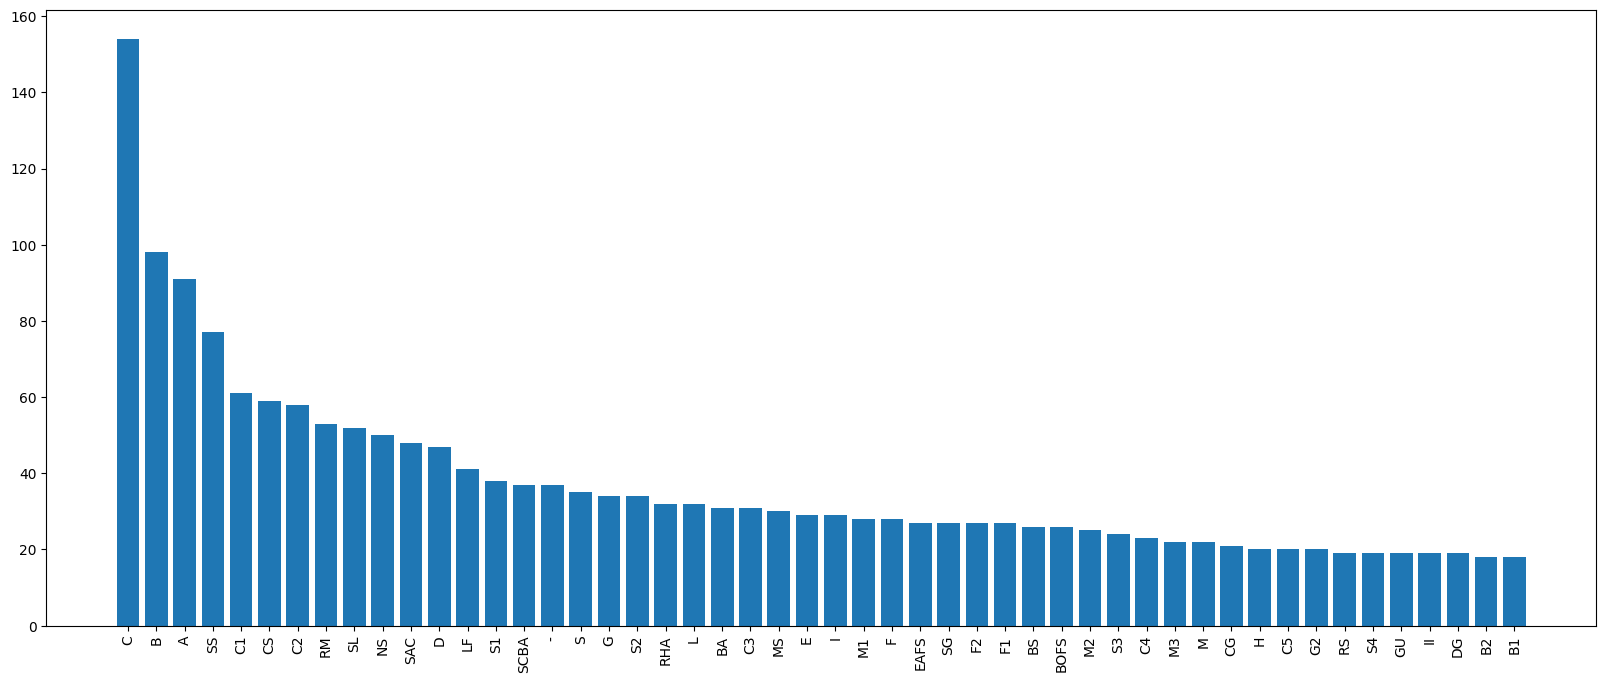

In [39]:
freq = list(dfnolabel2[mask2].paper_mid.value_counts()[:50].values)
labs = list(dfnolabel2[mask2].paper_mid.value_counts()[:50].index)

freq = ignored_freq[1:] + freq
labs =  ignored_labels[1:] + labs
fig, ax = plt.subplots(figsize=[20,8])
plt.bar(labs, freq)
plt.xticks(rotation=90)
plt.show()

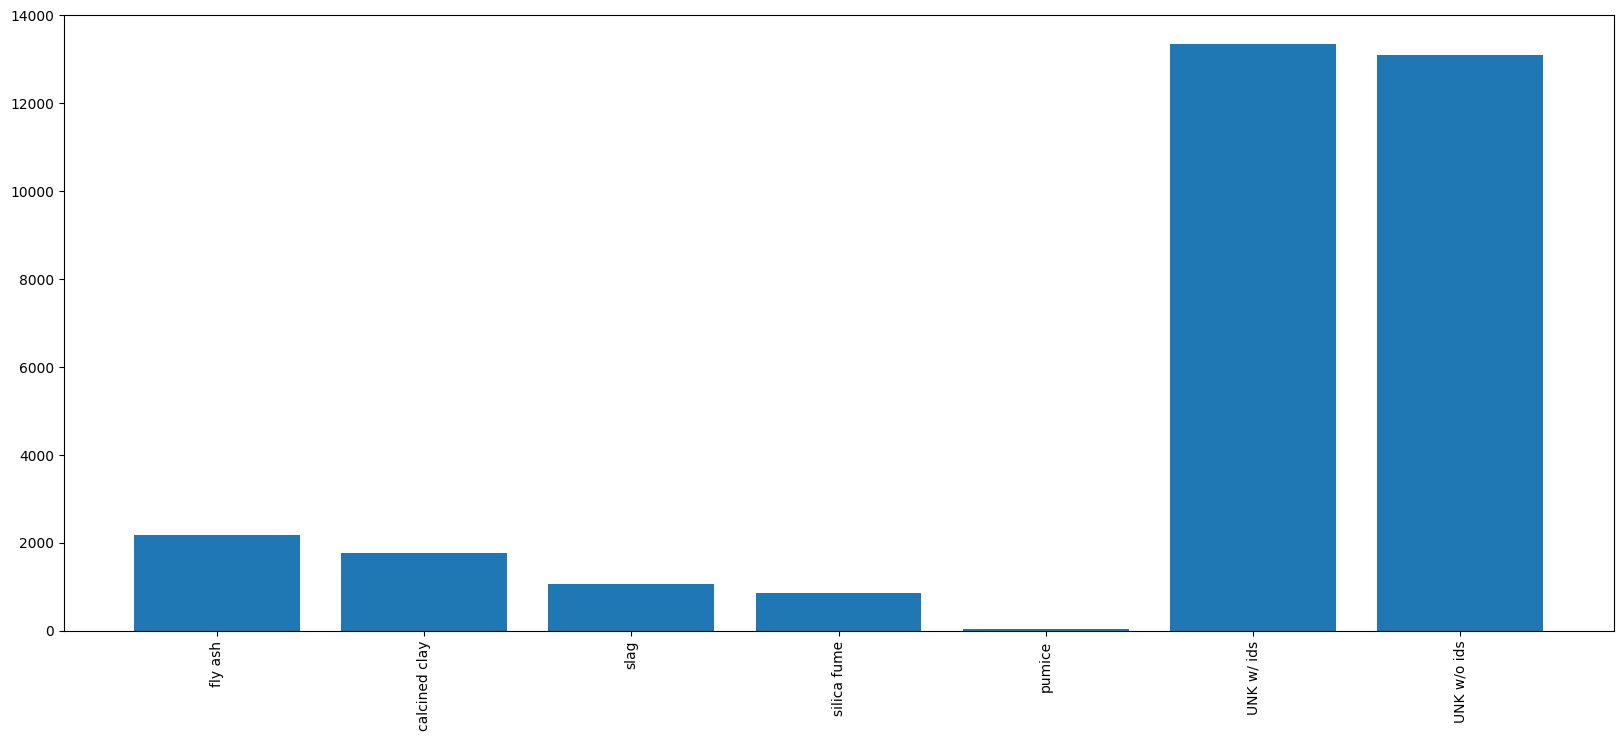

In [42]:
freq = list(dfnolabel2[mask2].paper_mid.value_counts()[:].values)
labs = list(dfnolabel2[mask2].paper_mid.value_counts()[:].index)

freq = scm_freq + ignored_freq[1:] + [sum(freq)] + [13107]
labs = scm_label + ignored_labels[1:] + ['UNK w/ ids'] + ['UNK w/o ids']
fig, ax = plt.subplots(figsize=[20,8])
plt.bar(labs, freq)
plt.xticks(rotation=90)
plt.show()

In [43]:
freq

[2185, 1764, 1064, 857, 34, 13348, 13107]

In [44]:
labs

['fly ash',
 'calcined clay',
 'slag',
 'silica fume',
 'pumice',
 'UNK w/ ids',
 'UNK w/o ids']

In [45]:
# dfnolabel2[mask].caption.unique()

In [46]:
def fine_labeller(x):
    label = []
    for wlist in ignored_list:
        for w in wlist:
            x = str(x)
            if w in x.lower():
                if w not in label:
                    label.append(w)
    return str(label)

In [47]:
dfnolabel3 = dfnolabel2[mask]
dfnolabel3['r3'] = dfnolabel3.caption.apply(lambda x: fine_labeller(x))

/var/tmp/pbs.94917.pbshpc/ipykernel_29619/373994474.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dfnolabel3['r3'] = dfnolabel3.caption.apply(lambda x: fine_labeller(x))


In [48]:
dfnolabel3.r3.value_counts()

r3
[]                               4958
['cement', 'cem']                2255
['ls']                           1135
['portland', 'cement', 'cem']     706
['cement', 'cem', 'physical']     460
                                 ... 
['cac', 'gp', 'physical']           1
['bauxite', 'clay']                 1
['magnetite']                       1
['aggregate', 'agg', 'clay']        1
['lime', 'mud']                     1
Name: count, Length: 247, dtype: int64

In [49]:
dfnolabel4 = dfnolabel3[dfnolabel3['r3'] == '[]']

In [50]:
dfnolabel4.total.median()


0.33333

In [55]:
dfnolabel4[dfnolabel4.total.between(80,110)].shape#[50:]#.sum()

(1562, 18)

In [79]:
dfnolabel3 = dfnolabel2[dfnolabel2['r3']=='[]']

words_all = ' '.join(list(dfnolabel3.caption.unique())).split()

stops = ['of','and','the','in','by','used','for','on','from','this','at','to','as','different','with','determined','results', '%).', '(%','studied']
words_all = [str(x).lower() for x in words_all if str(x).lower() not in stops]

In [91]:
dfnolabel3

(10565, 18)

In [90]:
df3_80_100 = dfnolabel3[dfnolabel3.total.between(75,110)]
df3_80_100#.total.hist()

,SiO2,Al2O3,Fe2O3,CaO,Na2O,K2O,MgO,SO3,mid,pii_tid,label,total,caption,caption_id,r1,r2,paper_mid,r3
25,54.83,19.05,6.00,9.39,0.50,0.00,0.00,2.900,S0008884600002453_2_1_1_0_B,S0008884600002453_2,[],92.670,"Composition of GB types B, D, L, P, and L1\na",S0008884600002453_2_1_1_0_B,[],[],B,[]
26,69.99,10.62,4.02,8.86,1.02,0.00,0.00,0.038,S0008884600002453_2_2_1_0_D,S0008884600002453_2,[],94.548,"Composition of GB types B, D, L, P, and L1\na",S0008884600002453_2_2_1_0_D,[],[],D,[]
27,68.79,15.23,6.28,1.79,0.26,0.00,0.00,0.127,S0008884600002453_2_3_1_0_L,S0008884600002453_2,[],92.477,"Composition of GB types B, D, L, P, and L1\na",S0008884600002453_2_3_1_0_L,[],[],L,[]
28,72.75,15.89,4.97,0.87,0.27,0.00,0.00,0.070,S0008884600002453_2_4_1_0_P,S0008884600002453_2,[],94.820,"Composition of GB types B, D, L, P, and L1\na",S0008884600002453_2_4_1_0_P,[],[],P,[]
29,58.02,15.28,6.26,8.07,0.71,0.00,0.00,0.139,S0008884600002453_2_5_1_0_L1,S0008884600002453_2,[],88.479,"Composition of GB types B, D, L, P, and L1\na",S0008884600002453_2_5_1_0_L1,[],[],L1,[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40420,3.60,6.30,0.80,56.90,0.00,0.30,1.70,24.600,S0958946523003980_0_1_1_0,S0958946523003980_0,[],94.200,Oxide composition.,S0958946523003980_0_1_1_0,[],[],0,[]
40421,14.00,20.90,3.60,39.80,0.20,0.50,2.80,14.500,S0958946523003980_0_2_1_0,S0958946523003980_0,[],96.300,Oxide composition.,S0958946523003980_0_2_1_0,[],[],0,[]
40422,18.90,5.20,5.70,63.30,0.00,0.60,0.90,2.700,S0958946523003980_0_3_1_0,S0958946523003980_0,[],97.300,Oxide composition.,S0958946523003980_0_3_1_0,[],[],0,[]
40436,34.79,15.63,12.20,4.77,1.51,1.87,2.19,3.360,S0958946523004110_0_3_1_0_MS,S0958946523004110_0,[],76.320,Major chemical composition and ignition loss (...,S0958946523004110_0_3_1_0_MS,[],[],MS,[]


In [85]:
dfnolabel3[dfnolabel3.caption.apply(lambda x: 'steel' in x.lower())]

,SiO2,Al2O3,Fe2O3,CaO,Na2O,K2O,MgO,SO3,mid,pii_tid,label,total,caption,caption_id,r1,r2,paper_mid,r3
1686,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0008884606000706_2_1_6_0,S0008884606000706_2,[],0.0,Chemical composition of mild steel bars (wt. %),S0008884606000706_2_1_6_0,[],[],0,[]
2463,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0008884609003366_0_2_0_0_FeCr12 (M),S0008884609003366_0,[],0.0,Chemical and structural composition of stainle...,S0008884609003366_0_2_0_0_FeCr12 (M),[],[],FeCr12 (M),[]
2464,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0008884609003366_0_3_0_0_FeCr16 (F),S0008884609003366_0,[],0.0,Chemical and structural composition of stainle...,S0008884609003366_0_3_0_0_FeCr16 (F),[],[],FeCr16 (F),[]
2465,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0008884609003366_0_4_0_0_FeCr18Ni10 (A),S0008884609003366_0,[],0.0,Chemical and structural composition of stainle...,S0008884609003366_0_4_0_0_FeCr18Ni10 (A),[],[],FeCr18Ni10 (A),[]
2466,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0008884609003366_0_5_0_0_FeCr18Ni10Mo2 (A),S0008884609003366_0,[],0.0,Chemical and structural composition of stainle...,S0008884609003366_0_5_0_0_FeCr18Ni10Mo2 (A),[],[],FeCr18Ni10Mo2 (A),[]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39379,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0958946522001330_3_1_2_0,S0958946522001330_3,[],0.0,Composition of steel 10216 (GD-OES).,S0958946522001330_3_1_2_0,[],[],0,[]
39755,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0958946522003857_3_1_1_0,S0958946522003857_3,[],0.0,Atomic composition of particles removed from s...,S0958946522003857_3_1_1_0,[],[],0,[]
39756,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0958946522003857_3_2_1_0,S0958946522003857_3,[],0.0,Atomic composition of particles removed from s...,S0958946522003857_3_2_1_0,[],[],0,[]
39757,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,S0958946522003857_3_3_1_0,S0958946522003857_3,[],0.0,Atomic composition of particles removed from s...,S0958946522003857_3_3_1_0,[],[],0,[]


In [83]:
pd.Series(words_all).value_counts()[:10]

chemical        1952
composition     1543
compositions     506
analysis         189
(wt%).           133
steel            127
(%).             126
fly              124
oxide            116
properties       114
Name: count, dtype: int64

In [61]:
# dfnolabel3

In [49]:
dfnolabel2[mask]['pii_tid'].value_counts()#.shape

pii_tid
S0008884617312073_4    120
S0958946517306297_4    104
S0950061816315173_3     90
S0958946517306297_5     79
S0008884623001643_5     61
                      ... 
S0950061818322724_0      1
S0950061818322566_0      1
S0950061818322542_0      1
S0950061818322517_2      1
S0958946599000396_2      1
Name: count, Length: 6242, dtype: int64

In [ ]:
# S0008884623001643_5 check this in unk w/o ids
# S095006182031480X_1 ids are numbers itself

In [37]:
dfnolabel2[mask2].paper_mid.value_counts()[:50]

paper_mid
C       154
B        98
A        91
SS       77
C1       61
CS       59
C2       58
RM       53
SL       52
NS       50
SAC      48
D        47
LF       41
S1       38
SCBA     37
-        37
S        35
G        34
S2       34
RHA      32
L        32
BA       31
C3       31
MS       30
E        29
I        29
M1       28
F        28
EAFS     27
SG       27
F2       27
F1       27
BS       26
BOFS     26
M2       25
S3       24
C4       23
M3       22
M        22
CG       21
H        20
C5       20
G2       20
RS       19
S4       19
GU       19
II       19
DG       19
B2       18
B1       18
Name: count, dtype: int64

In [107]:
df10k = dfnolabel2[mask2]

In [81]:
df10k['pii_tid_mid'] = df10k['pii_tid'] + '_' + df10k['paper_mid']

/var/tmp/pbs.69681.pbshpc/ipykernel_22422/539085735.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df10k['pii_tid_mid'] = df10k['pii_tid'] + '_' + df10k['paper_mid']


In [77]:
# print(list(df10k['paper_mid'].value_counts().index))#[:50]

In [110]:
df10k[df10k.paper_mid=='BOFS']

,SiO2,Al2O3,Fe2O3,CaO,Na2O,K2O,MgO,SO3,mid,pii_tid,label,total,caption,caption_id,r1,paper_mid
2639,18.94,2.91,8.85,40.01,0.00,0.00,5.36,0.35,S0008884610002619_0_2_1_0_BOFS,S0008884610002619_0,[],76.42,"Composition of OPC, BOFS and EAFS/mass%.",S0008884610002619_0_2_1_0_BOFS,[],BOFS
5985,15.30,1.00,23.30,50.40,0.00,0.00,2.01,0.00,S0008884621001678_1_2_1_0_BOFS,S0008884621001678_1,[],92.01,Chemical composition of BOFS and non-metallic ...,S0008884621001678_1_2_1_0_BOFS,[],BOFS
5986,12.07,1.79,28.59,43.48,0.07,0.03,3.64,0.23,S0008884621001678_2_1_1_0_BOFS,S0008884621001678_2,[],89.90,Chemical composition of the original BOFS and ...,S0008884621001678_2_1_1_0_BOFS,[],BOFS
10240,18.94,2.91,8.85,40.01,0.00,0.00,5.36,0.88,S095006181300682X_0_1_1_0_BOFS,S095006181300682X_0,[],76.95,Chemical compositions of materials (wt%).,S095006181300682X_0_1_1_0_BOFS,[],BOFS
10247,19.93,2.24,22.68,50.09,0.00,0.00,1.38,0.48,S095006181300682X_4_6_1_0_BOFS,S095006181300682X_4,[],96.80,Chemical compositions and physical and cementi...,S095006181300682X_4_6_1_0_BOFS,[],BOFS
17102,13.46,3.56,21.78,45.16,0.08,0.01,9.60,0.00,S0950061818313047_0_1_3_0_BOFS,S0950061818313047_0,[],93.65,"Chemical compositions (wt%) of cement, FA, BOF...",S0950061818313047_0_1_3_0_BOFS,[],BOFS
18823,16.15,4.31,27.03,41.03,0.20,0.17,3.64,0.16,S0950061819302338_0_2_1_0_BOFS,S0950061819302338_0,[],92.69,Oxide composition (mass %) and Blaine fineness...,S0950061819302338_0_2_1_0_BOFS,[],BOFS
18916,13.40,3.60,34.50,36.20,0.00,0.00,5.00,0.30,S0950061819303496_0_1_1_0_BOFS,S0950061819303496_0,[],93.00,Chemical composition of the raw wastes.,S0950061819303496_0_1_1_0_BOFS,[],BOFS
24411,14.40,3.80,31.80,36.90,0.00,0.00,5.80,0.30,S0950061820336448_0_1_1_0_BOFS,S0950061820336448_0,[],93.00,Semiquantitative chemical composition of the s...,S0950061820336448_0_1_1_0_BOFS,[],BOFS
25832,11.97,2.16,0.00,39.40,0.30,0.00,6.27,0.12,S0950061821010254_0_11_2_0_BOFS,S0950061821010254_0,[],60.22,Chemical composition of steel slag from the re...,S0950061821010254_0_11_2_0_BOFS,[],BOFS


In [28]:
# df10k[df10k.paper_mid=='PG']

In [29]:
pii_tid_mid_sentences = dict()
for pii_tid in df10k['pii_tid']:
    dffiltered = df10k[df10k.pii_tid == pii_tid]
    unique_mids = list(dffiltered.paper_mid.unique())
    pii_tid_mid_sentences[pii_tid] = dict()
    for m in unique_mids:
        pii_tid_mid_sentences[pii_tid][m] = []
        
    
    # break

In [30]:

len(list(pii_tid_mid_sentences.keys()))

5843

In [84]:
# S0008884604004545_0
pii_wanted = 'S0008884603001121'
for j in alldata_dicts:
    
    if pii_wanted in list(j.keys()):
        paper = j[pii_wanted]
        break

In [85]:
paper[3]

{'doi': '10.1016/S0008-8846(03)00112-1',
 'act_table': [['Mineral admixture', 'FA', 'SP', 'LP', 'SF'],
  ['SiO2 (%)', '42.88', '57.46', '9.28', '94.96'],
  ['Al2O3 (%)', '16.10', '18.63', '3.80', '0.36'],
  ['Fe2O3 (%)', '9.90', '7.43', '1.80', '0.40'],
  ['CaO (%)', '15.90', '3.36', '42.25', '0.45'],
  ['MgO (%)', '0.73', '1.13', '2.96', '0.99'],
  ['SO3 (%)', '6.42', '0.14', '1.96', '0.16'],
  ['LOI (%)', '1.74', '5.38', '37.45', '0.58']],
 'caption': 'Chemical compositions of mineral admixtures',
 'footer': {}}

In [1]:
# paper
import pickle

In [2]:
with open('./Cement_and_Concrete_Composites/inference_paper_text.pkl','rb') as f:
    jtccc = pickle.load(f)
jtccc_piis = list(jtccc.keys())
f.close()

with open('./Cement_and_Concrete_Research/inference_paper_text.pkl','rb') as f:
    jtccr = pickle.load(f)
f.close()
jtccr_piis = list(jtccr.keys())
with open('./Construction_and_Building_Materials/inference_paper_text.pkl','rb') as f:
    jtcbm = pickle.load(f)
f.close()
jtcbm_piis = list(jtcbm.keys())

In [3]:
len(jtccc_piis), len(jtccr), len(jtcbm)

(4024, 5286, 31265)

In [4]:
len(jtccc_piis)+ len(jtccr)+ len(jtcbm)

40575

In [6]:
pwd

'/home/civil/phd/cez198233/users/Tanishq/DiSCoMaT/code_and_data/code/inference/bigdata'

In [87]:
def fetch_paper_text(pii):
    if pii in jtccc_piis:
        return jtccc[pii]
    
    elif pii in jtccr_piis:
        return jtccr[pii]
    
    elif pii in jtcbm_piis:
        return jtcbm[pii]
    
    else:
        print('Please check pii. It is currently not present in our DB.')
        return None

In [47]:
# fetch_paper_text('S0008884603001121')

In [37]:
import matplotlib.pyplot as plt

In [38]:
df10k['mid_len'] = df10k.paper_mid.apply(lambda x: len(x))

/var/tmp/pbs.69620.pbshpc/ipykernel_17240/54447672.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df10k['mid_len'] = df10k.paper_mid.apply(lambda x: len(x))


In [39]:
# pd.read_csv('cement_all_comps.csv').shape

In [40]:
df7k = dfnolabel2[mask]

In [42]:
pwd

'/home/civil/phd/cez198233/users/Tanishq/DiSCoMaT/code_and_data/code/inference/bigdata'

In [41]:
df7k

,SiO2,Al2O3,Fe2O3,CaO,Na2O,K2O,MgO,SO3,mid,pii_tid,label,total,caption,caption_id,r1,paper_mid
17,21.6,4.20,3.0,62.8,0.41,0.41,3.1,2.5,S0008884600002349_0_1_1_0,S0008884600002349_0,[],98.02,Chemical composition of raw materials\nNA=not ...,Chemical composition of raw materials\nNA=not ...,[],0
18,35.3,9.90,0.6,34.7,0.30,0.40,14.6,4.0,S0008884600002349_0_1_2_0,S0008884600002349_0,[],99.80,Chemical composition of raw materials\nNA=not ...,Chemical composition of raw materials\nNA=not ...,[],0
19,46.9,25.40,8.2,3.7,0.30,1.70,1.0,0.9,S0008884600002349_0_1_3_0,S0008884600002349_0,[],88.10,Chemical composition of raw materials\nNA=not ...,Chemical composition of raw materials\nNA=not ...,[],0
20,4.5,41.20,11.3,39.8,0.10,0.10,0.6,0.0,S0008884600002349_0_1_4_0,S0008884600002349_0,[],97.60,Chemical composition of raw materials\nNA=not ...,Chemical composition of raw materials\nNA=not ...,[],0
21,0.3,0.01,0.1,33.5,0.01,0.02,0.5,45.2,S0008884600002349_0_1_7_0,S0008884600002349_0,[],79.64,Chemical composition of raw materials\nNA=not ...,Chemical composition of raw materials\nNA=not ...,[],0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40422,18.9,5.20,5.7,63.3,0.00,0.60,0.9,2.7,S0958946523003980_0_3_1_0,S0958946523003980_0,[],97.30,Oxide composition.,Oxide composition._S0958946523003980_0_3_1_0,[],0
40443,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0,S0958946599000086_0_2_0_0,S0958946599000086_0,[],0.00,Weight composition of the standardized samples,Weight composition of the standardized samples...,[],0
40444,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0,S0958946599000086_0_3_0_0,S0958946599000086_0,[],0.00,Weight composition of the standardized samples,Weight composition of the standardized samples...,[],0
40445,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0,S0958946599000086_0_4_0_0,S0958946599000086_0,[],0.00,Weight composition of the standardized samples,Weight composition of the standardized samples...,[],0


In [16]:
mask = df.label.apply(lambda x: x in ['[0]', '[2]', '[3]', '[1]', '[4]'])

In [5]:
STRR = 'S0008884604001498_4'
# S0008884621003215_1
pii = STRR.split('_')[0]
idx = STRR.split('_')[-1]

for p in alldata_dicts:
    try:
        print(p[pii][int(idx)]['caption'])
        
        print(p[pii][int(idx)]['act_table'])
        display(pd.DataFrame(p[pii][int(idx)]['act_table']))
    except Exception as e:
        print(e)
        pass

Solubility constants of solid phases found in hydrated cement systems
[['Name', 'Chemical formula', 'Expression for equilibrium (K sp)', '-log K sp'], ['Portlandite', 'Ca(OH)2', '{Ca}{OH}2', '5.2'], ['C-S-H', '0.65Ca(OH)2+ CaH2SiO4', '{Ca}{OH}2', '6.2'], ['Ettringite', '3CaO*Al2O3*3CaSO4*32H2O', '{Ca}6{OH}4{SO4}3{Al(OH)4}2', '44.0'], ['Monosulfate', '3CaO*Al2O3*CaSO4*12H2O', '{Ca}4{OH}4{SO4}{Al(OH)4}2', '29.4'], ['Gypsum', 'CaSO4*2H2O', '{Ca}{SO4}', '4.6'], ['Mirabilite', 'Na2SO4*10H2O', '{Na}2{SO4}', '1.2']]


,0,1,2,3
0,Name,Chemical formula,Expression for equilibrium (K sp),-log K sp
1,Portlandite,Ca(OH)2,{Ca}{OH}2,5.2
2,C-S-H,0.65Ca(OH)2+ CaH2SiO4,{Ca}{OH}2,6.2
3,Ettringite,3CaO*Al2O3*3CaSO4*32H2O,{Ca}6{OH}4{SO4}3{Al(OH)4}2,44.0
4,Monosulfate,3CaO*Al2O3*CaSO4*12H2O,{Ca}4{OH}4{SO4}{Al(OH)4}2,29.4
5,Gypsum,CaSO4*2H2O,{Ca}{SO4},4.6
6,Mirabilite,Na2SO4*10H2O,{Na}2{SO4},1.2


'S0008884604001498'
'S0008884604001498'


In [8]:
# 5*df.label.value_counts()/59.04

In [9]:
# 2185+1764+1064+857+34

In [55]:
np.random.seed(0)
df[df.label=='[0]'].sample(185).to_csv('0_flyash_185.csv',index=False)

In [56]:
np.random.seed(0)
df[df.label=='[2]'].sample(150).to_csv('2_slags_150.csv',index=False)

In [57]:
np.random.seed(0)
df[df.label=='[3]'].sample(91).to_csv('3_slags_91.csv',index=False)

In [58]:
np.random.seed(0)
df[df.label=='[1]'].sample(73).to_csv('1_clays_73.csv',index=False)

In [59]:
np.random.seed(0)
df[df.label=='[4]'].sample(34).to_csv('4_pumice_34.csv',index=False)

In [10]:
str_list = [['fly ash', 'pfa', 'fa', 'pulverized fuel ash'],
 ['calcined clay', 'cc', 'metakaolin', 'mk', 'calcined kaolinite'],
 ['slag', 'ggbs', 'bfs'],
 ['silica fume', 'sf', 'fumed silica'],
 ['pumice']]

In [11]:
df

,SiO2,Al2O3,Fe2O3,CaO,Na2O,K2O,MgO,SO3,mid,pii_tid,label,total,caption
0,48.80,26.80,7.40,4.60,0.67,3.60,1.90,0.00,S0008884600001988_0_1_3_0_FA-A,S0008884600001988_0,[0],93.77,Chemical composition of the two starting fly a...
1,45.20,25.30,9.10,6.70,0.48,3.20,1.70,0.00,S0008884600001988_0_2_3_0_FA-B,S0008884600001988_0,[0],91.68,Chemical composition of the two starting fly a...
2,26.80,14.70,3.60,49.30,0.30,1.10,1.30,0.60,S0008884600001988_0_3_3_0_FABC-A,S0008884600001988_0,[0],97.70,Chemical composition of the two starting fly a...
3,26.70,16.40,4.60,47.40,0.20,0.98,1.30,0.60,S0008884600001988_0_4_3_0_FABC-B,S0008884600001988_0,[0],98.18,Chemical composition of the two starting fly a...
4,21.17,5.34,2.28,63.92,0.47,0.00,3.91,2.32,S0008884600002003_1_1_1_0_Type I cement,S0008884600002003_1,[],99.41,Composition of the cementing materials
...,...,...,...,...,...,...,...,...,...,...,...,...,...
40449,0.36,0.16,0.16,31.38,0.00,0.00,20.98,0.00,S0958946599000220_0_2_1_0_Dolomite (NM-0),S0958946599000220_0,[],53.04,The chemical composition of the rocks (wt%)
40450,20.40,4.89,3.18,64.02,0.07,0.53,2.56,2.85,S0958946599000311_1_0_1_0,S0958946599000311_1,[],98.50,Composition of the cement
40451,21.30,5.30,0.00,64.40,0.20,0.60,2.20,1.90,S0958946599000347_0_9_2_0_OPC,S0958946599000347_0,[],95.90,Physical properties and main chemical composit...
40452,33.70,13.40,0.00,41.90,0.20,0.30,7.10,0.00,S0958946599000347_0_9_4_0_BFS,S0958946599000347_0,[2],96.60,Physical properties and main chemical composit...


In [26]:
df[mask].label.value_counts()

label
[0]    2185
[2]    1764
[3]    1064
[1]     857
[4]      34
Name: count, dtype: int64

In [25]:
df[mask].sample(500).label.value_counts()

label
[0]    186
[2]    158
[3]     92
[1]     61
[4]      3
Name: count, dtype: int64